# Most and Least Relevant Firms

| Item | Description |
|---|---|
| Goal | Figure B of the plan: for each relevance measure, one single-panel figure with horizontal bars for the ten most relevant and the ten least relevant firms on the sample set by `SAMPLE`, firm names on the Y-axis. |
| Input | `output/T3.8.3/firm_relevance_scores_wide.csv` (T3.8.3). |
| Output | `output/T3.9.2/fig_firms_<method>_<vector>_<measure>.{png,svg,pdf}`, one figure per measure. |
| Unit | A firm (gvkey) in the sample set by `SAMPLE`: all years (every fiscal year a firm filed, 1999 to 2025; 1,058 firms) or the three years (fiscal 2010, 2015, 2020; 841 firms). |
| Measures | The eight non-binary measures of T3.8.3. For the two share measures most firms tie at 0, so those figures show the ten most relevant firms only and the Notes give the number of firms at 0. |
| Style | S3: 9 by 6 inches, Times, 0.5 cm margins, legend one row below the X-title, no text inside the plot, title and notes in Markdown below. Industry coloring is deferred (open item). |

See `README.md` in the TEMP folder for the surrounding steps and `T3.8.3` for what each measure is.


## Step 1. Import packages


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display


## Step 2. Define file locations and the measures to plot


In [2]:
PROJECT_FOLDER = Path("/project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis")
NOTEBOOK_SUBFOLDER = Path("T3 - Topic Relevance and Corporate Disclosure/TEMP")
NOTEBOOK_NAME = "T3.9.2"  # the identifier names this notebook's output folder
TEMP_OUTPUT = PROJECT_FOLDER / NOTEBOOK_SUBFOLDER / "output"
OUTPUT_FOLDER = TEMP_OUTPUT / NOTEBOOK_NAME
SCORES_FILE = TEMP_OUTPUT / "T3.8.3/firm_relevance_scores_wide.csv"

SAMPLE = "all_years"  # the main sample; "three_years" for the three-year figures
SAMPLE_WORDS = {"three_years": "the three-year sample (fiscal years 2010, 2015, and 2020)", "all_years": "the all-years sample (every fiscal year a firm filed, 1999 to 2025)"}
N_TOP = 10
VECTOR_WORDS = {"definition": "the topic definition", "centroid": "the statement centroid", "policy_summary": "the policy summary"}
# measure_id -> (file stem, x-title, one-sentence description for the Notes)
MEASURES = {
    "sentences | definition | share": ("fig_firms_sentences_definition_share",
        "Share of Item 1 sentences at or above the definition threshold (share)",
        "the number of the firm's Item 1 sentences whose cosine with the topic definition is at or above 0.67, divided by all its Item 1 sentences in the sample"),
    "sentences | centroid | share": ("fig_firms_sentences_centroid_share",
        "Share of Item 1 sentences at or above the centroid threshold (share)",
        "the number of the firm's Item 1 sentences whose cosine with the statement centroid is at or above 0.75, divided by all its Item 1 sentences in the sample"),
    "summaries | definition | firm_summary": ("fig_firms_summaries_definition_firm_summary",
        "Cosine between the firm summary and the topic definition (cosine)",
        "the cosine between the embedding of the firm's summary of its Item 1 sections and the embedding of the topic definition"),
    "summaries | definition | yearly_mean": ("fig_firms_summaries_definition_yearly_mean",
        "Mean cosine between the yearly summaries and the topic definition (cosine)",
        "the cosine between each yearly Item 1 summary and the topic definition, averaged over the firm's fiscal years in the sample"),
    "summaries | centroid | firm_summary": ("fig_firms_summaries_centroid_firm_summary",
        "Cosine between the firm summary and the statement centroid (cosine)",
        "the cosine between the embedding of the firm's summary of its Item 1 sections and the centroid of the Topic 68 hearing statements"),
    "summaries | centroid | yearly_mean": ("fig_firms_summaries_centroid_yearly_mean",
        "Mean cosine between the yearly summaries and the statement centroid (cosine)",
        "the cosine between each yearly Item 1 summary and the centroid of the Topic 68 hearing statements, averaged over the firm's fiscal years in the sample"),
    "summaries | policy_summary | firm_summary": ("fig_firms_summaries_policy_summary_firm_summary",
        "Cosine between the firm summary and the policy summary (cosine)",
        "the cosine between the embedding of the firm's summary of its Item 1 sections and the embedding of the policy summary of the Topic 68 hearing statements"),
    "summaries | policy_summary | yearly_mean": ("fig_firms_summaries_policy_summary_yearly_mean",
        "Mean cosine between the yearly summaries and the policy summary (cosine)",
        "the cosine between each yearly Item 1 summary and the policy summary of the Topic 68 hearing statements, averaged over the firm's fiscal years in the sample"),
}
SOURCE = "10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; firm names from Compustat; authors' calculations"
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
print(f"Outputs: {OUTPUT_FOLDER}")


Outputs: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T3 - Topic Relevance and Corporate Disclosure/TEMP/output/T3.9.2


## Step 3. Figure style

The S3 settings: canvas, font, colors, horizontal background lines only.


In [3]:
RED = "#B31942"
BLUE = "#0A3161"
MIDNIGHT_BLUE = "#004953"
GREY = "#A6A6A8"
BLACK = "#101820"
FIGURE_WIDTH = 9
FIGURE_HEIGHT = 6
MARGIN_INCHES = 0.5 / 2.54
EXPORT_DPI = 300

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["font.size"] = 11
plt.rcParams["figure.figsize"] = (FIGURE_WIDTH, FIGURE_HEIGHT)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.unicode_minus"] = True
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.grid.axis"] = "y"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["grid.color"] = GREY
plt.rcParams["grid.linewidth"] = 0.5
plt.rcParams["text.color"] = BLACK
plt.rcParams["axes.labelcolor"] = BLACK
plt.rcParams["axes.edgecolor"] = BLACK
plt.rcParams["xtick.color"] = BLACK
plt.rcParams["ytick.color"] = BLACK


## Step 4. Load the scores and tidy the firm names

The wide table of T3.8.3, the chosen sample only. Compustat names are upper case; they are shown in title case with the common suffixes kept short.


In [4]:
wide = pd.read_csv(SCORES_FILE, dtype={"gvkey": str})
wide = wide.loc[wide["sample"].eq(SAMPLE)].reset_index(drop=True)
missing_columns = [m for m in MEASURES if m not in wide.columns]
assert not missing_columns, missing_columns
wide["display_name"] = wide["conm"].str.title().str.replace(r"\s+-Cl\s+\w+$", "", regex=True).str.replace(r"\bInc$", "Inc.", regex=True).str.replace(r"\bCorp$", "Corp.", regex=True)
assert wide["display_name"].is_unique, "two firms would share a label"
print(f"Firms in the {SAMPLE} sample: {len(wide):,}")
display(wide[["conm", "display_name"]].head(5))


Firms in the all_years sample: 1,058


,conm,display_name
0,ADC TELECOMMUNICATIONS INC,Adc Telecommunications Inc.
1,AMERICAN AIRLINES GROUP INC,American Airlines Group Inc.
2,PINNACLE WEST CAPITAL CORP,Pinnacle West Capital Corp.
3,ABBOTT LABORATORIES,Abbott Laboratories
4,ADVANCED MICRO DEVICES,Advanced Micro Devices


## Step 5. Draw one figure per measure

The ten most relevant firms in RED at the top and the ten least relevant in BLUE at the bottom, separated by an empty row, with the legend one row below the X-title. Where more than ten firms tie at the minimum (the share measures, where most firms score 0), only the ten most relevant are drawn and the Notes report the number at the minimum. Positions are measured after drawing so that the longest firm name starts 0.5 cm from the left edge and the legend ends 0.5 cm above the bottom edge.


In [5]:
figure_records = []
for figure_number, (measure_id, (figure_name, x_title, description)) in enumerate(MEASURES.items(), start=1):
    scored = wide[["display_name", measure_id]].dropna().rename(columns={measure_id: "score"}).sort_values("score", ascending=False)
    top = scored.head(N_TOP)
    n_at_minimum = int(scored["score"].eq(scored["score"].min()).sum())
    show_bottom = n_at_minimum <= N_TOP
    bottom = scored.tail(N_TOP).iloc[::-1] if show_bottom else scored.iloc[0:0]  # bottom group ordered from highest to lowest as well

    figure, axis = plt.subplots()
    figure.subplots_adjust(left=0.3, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.2)
    labels = top["display_name"].tolist() + ([""] + bottom["display_name"].tolist() if show_bottom else [])
    positions = np.arange(len(labels))[::-1]  # first label at the top
    axis.barh(positions[:len(top)], top["score"], color=RED, height=0.7, label=f"Ten most relevant firms", zorder=2)
    if show_bottom:
        axis.barh(positions[len(top) + 1:], bottom["score"], color=BLUE, height=0.7, label=f"Ten least relevant firms", zorder=2)
    axis.set_yticks(positions, labels=labels)
    axis.set_ylim(positions.min() - 0.6, positions.max() + 0.6)
    axis.set_xlim(0 if measure_id.endswith("| share") else float(scored["score"].min()) * 0.98, float(scored["score"].max()) * 1.02)
    axis.set_xlabel(x_title)
    axis.set_ylabel("Firm")
    axis.tick_params(axis="y", length=0)
    axis.spines[["top", "right"]].set_visible(False)
    legend = figure.legend(loc="lower left", bbox_to_anchor=(0, MARGIN_INCHES / FIGURE_HEIGHT), bbox_transform=figure.transFigure,
                           ncol=2, frameon=False, borderaxespad=0)

    figure.canvas.draw()
    renderer = figure.canvas.get_renderer()
    margin_pixels = MARGIN_INCHES * figure.dpi
    left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
    legend_top = legend.get_window_extent(renderer).y1
    bottom_shift = (legend_top + margin_pixels - axis.xaxis.label.get_window_extent(renderer).y0) / figure.bbox.height
    figure.subplots_adjust(left=figure.subplotpars.left + left_shift, bottom=figure.subplotpars.bottom + bottom_shift)
    figure.canvas.draw()
    legend.set_bbox_to_anchor((axis.yaxis.label.get_window_extent(renderer).x0 / figure.bbox.width, MARGIN_INCHES / FIGURE_HEIGHT), transform=figure.transFigure)
    for extension in ["png", "svg", "pdf"]:
        figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
    plt.close(figure)

    method, vector, measure = [part.strip() for part in measure_id.split("|")]
    tie_note = ("" if show_bottom else f" The ten least relevant firms are not drawn because {n_at_minimum:,} firms tie at the minimum score of {scored['score'].min():.3f}.")
    scope = ""
    notes = (f"Bars show the score, which is {description}, compared with {VECTOR_WORDS[vector]} of Topic 68, consumer data privacy legislation, "
             f"for the firms ranked highest{' and lowest' if show_bottom else ''} among the {len(scored):,} scored firms of {SAMPLE_WORDS[SAMPLE]}."
             f"{scope}{tie_note} Firm names are Compustat names in title case.")
    figure_records.append((figure_number, figure_name, measure_id, notes, show_bottom))
    print(f"Figure {figure_number}: {figure_name} (top {len(top)}, bottom {len(bottom)}; {n_at_minimum:,} firms at the minimum)")


Figure 1: fig_firms_sentences_definition_share (top 10, bottom 0; 752 firms at the minimum)


Figure 2: fig_firms_sentences_centroid_share (top 10, bottom 0; 793 firms at the minimum)


Figure 3: fig_firms_summaries_definition_firm_summary (top 10, bottom 10; 1 firms at the minimum)


Figure 4: fig_firms_summaries_definition_yearly_mean (top 10, bottom 10; 1 firms at the minimum)


Figure 5: fig_firms_summaries_centroid_firm_summary (top 10, bottom 10; 1 firms at the minimum)


Figure 6: fig_firms_summaries_centroid_yearly_mean (top 10, bottom 10; 1 firms at the minimum)


Figure 7: fig_firms_summaries_policy_summary_firm_summary (top 10, bottom 10; 1 firms at the minimum)


Figure 8: fig_firms_summaries_policy_summary_yearly_mean (top 10, bottom 10; 1 firms at the minimum)


## Step 6. Show the figures

Title, image, Notes, and Source for each figure, in that order. A figure that draws only the ten most relevant firms is titled accordingly.


**Figure 1. Most Relevant Firms by the Share of Sentences with the Definition Vector**

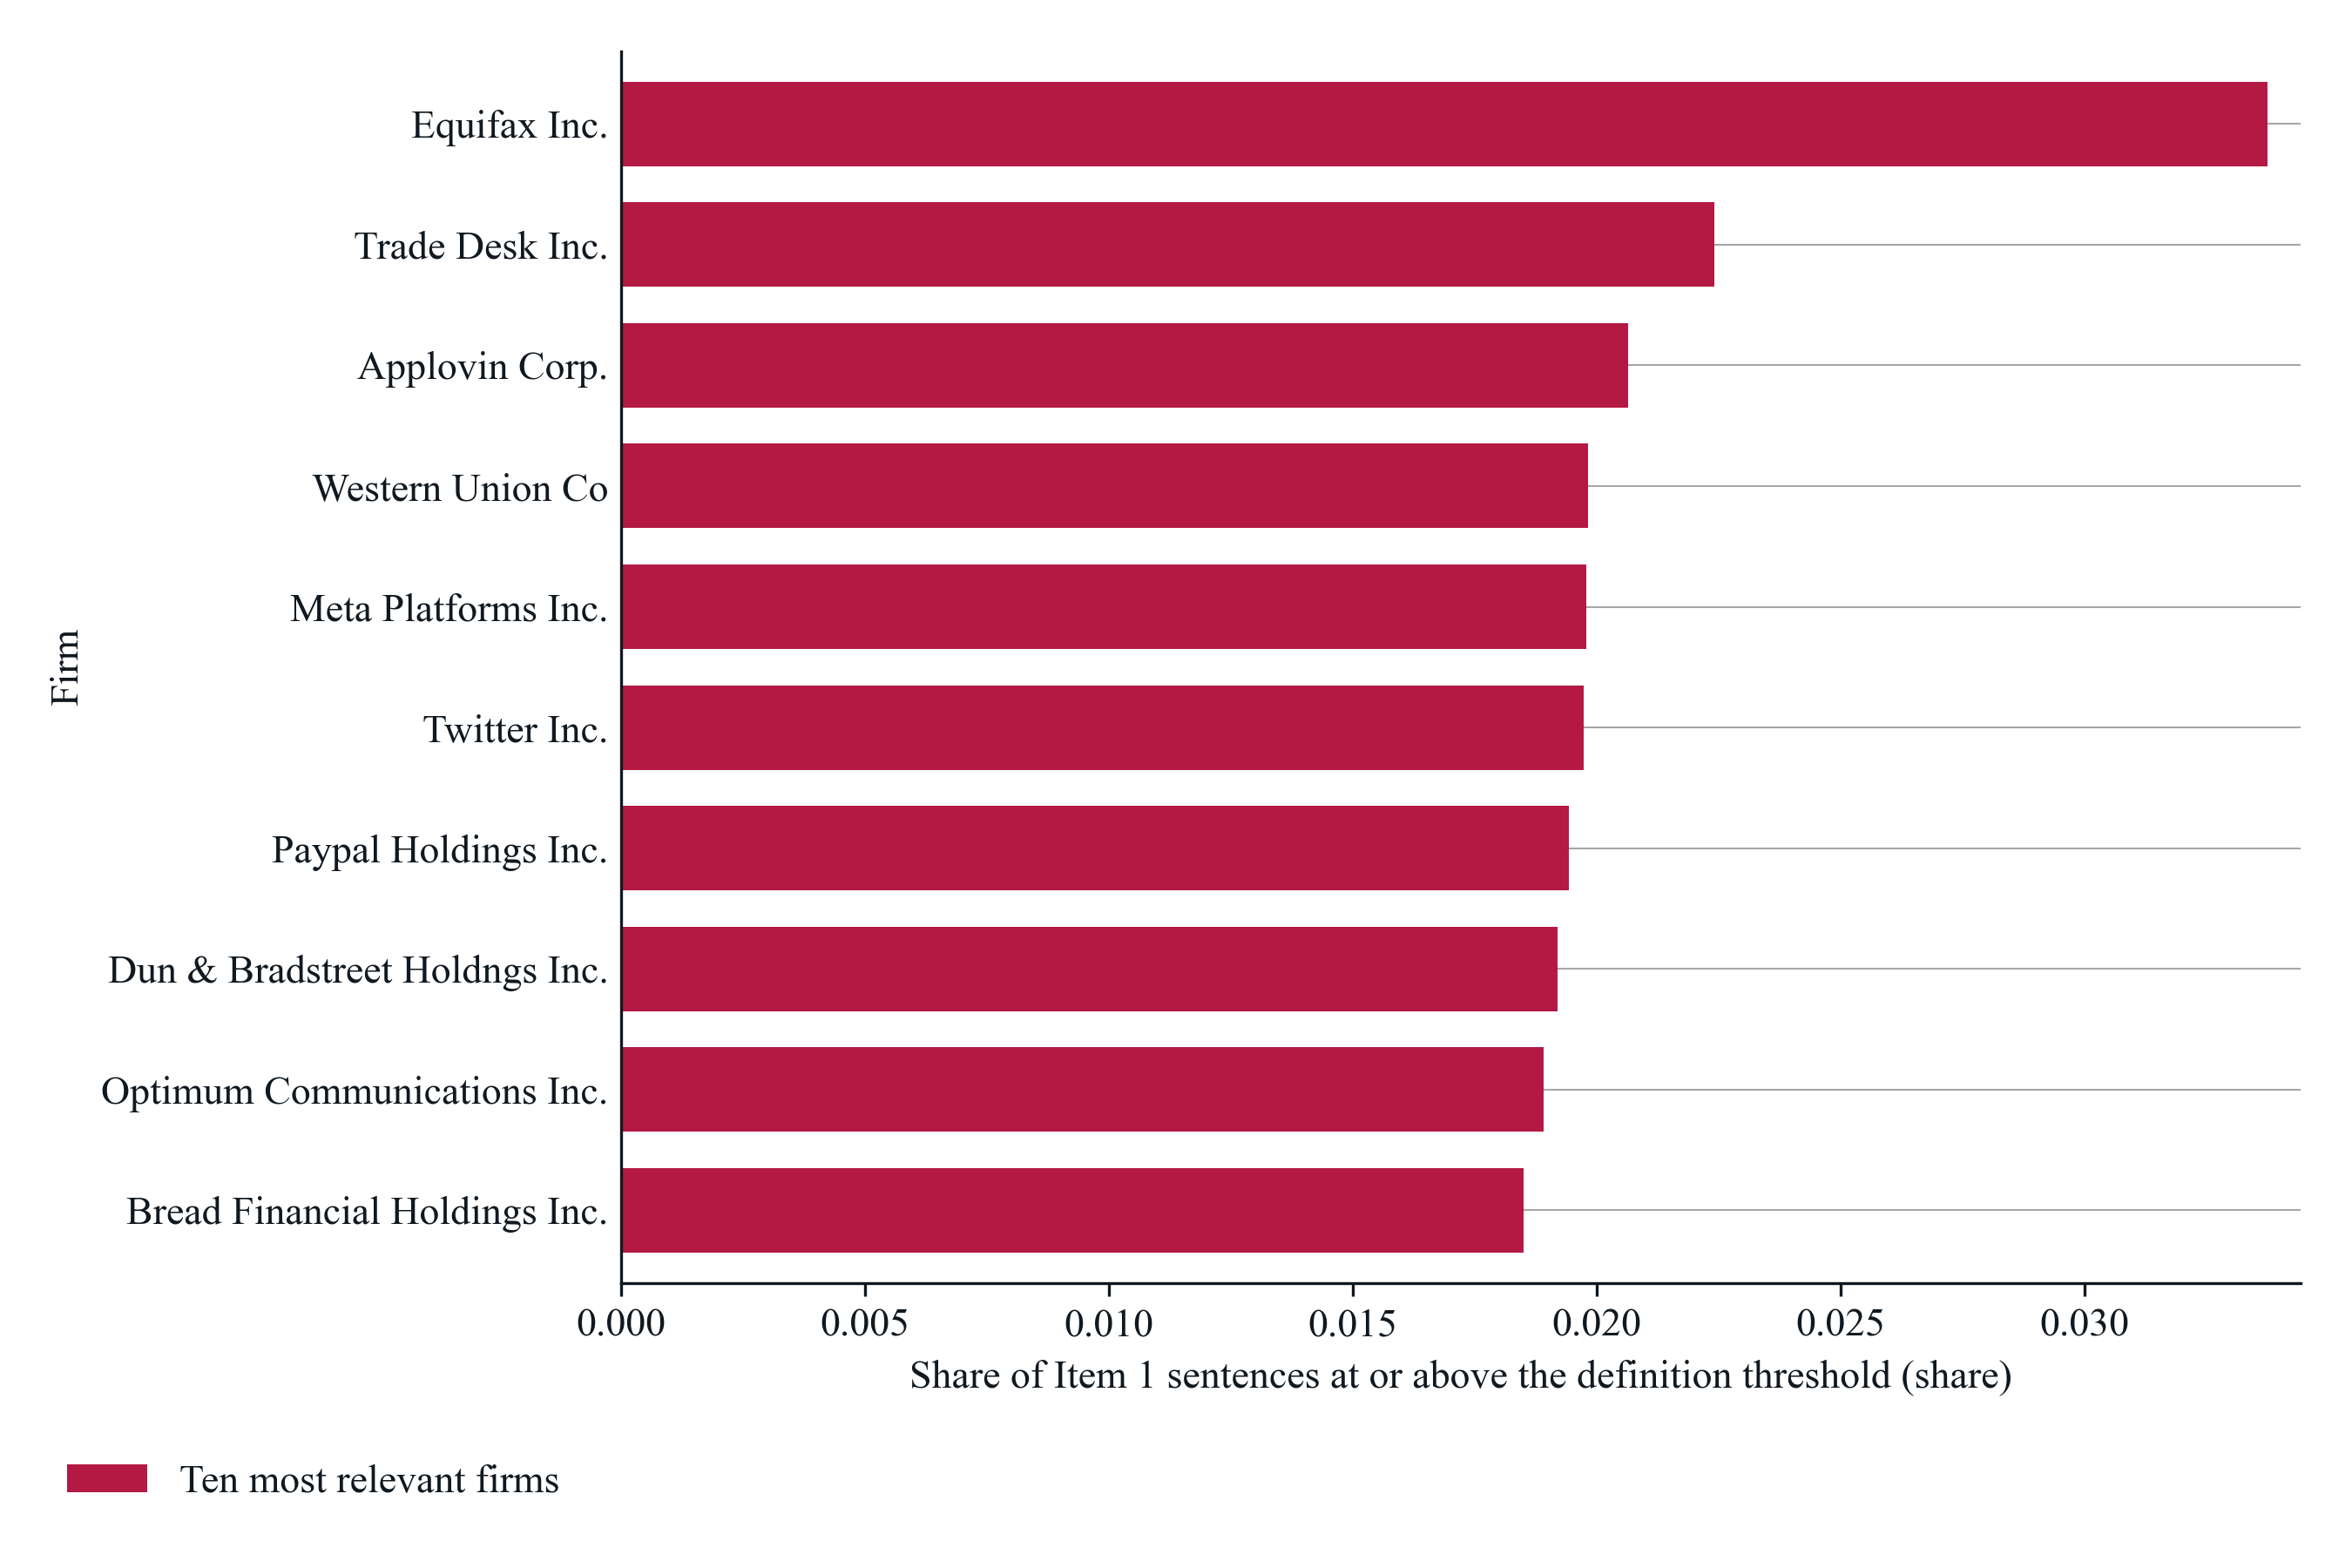

*Notes*: Bars show the score, which is the number of the firm's Item 1 sentences whose cosine with the topic definition is at or above 0.67, divided by all its Item 1 sentences in the sample, compared with the topic definition of Topic 68, consumer data privacy legislation, for the firms ranked highest among the 1,058 scored firms of the all-years sample (every fiscal year a firm filed, 1999 to 2025). The ten least relevant firms are not drawn because 752 firms tie at the minimum score of 0.000. Firm names are Compustat names in title case.

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; firm names from Compustat; authors' calculations.

**Figure 2. Most Relevant Firms by the Share of Sentences with the Centroid Vector**

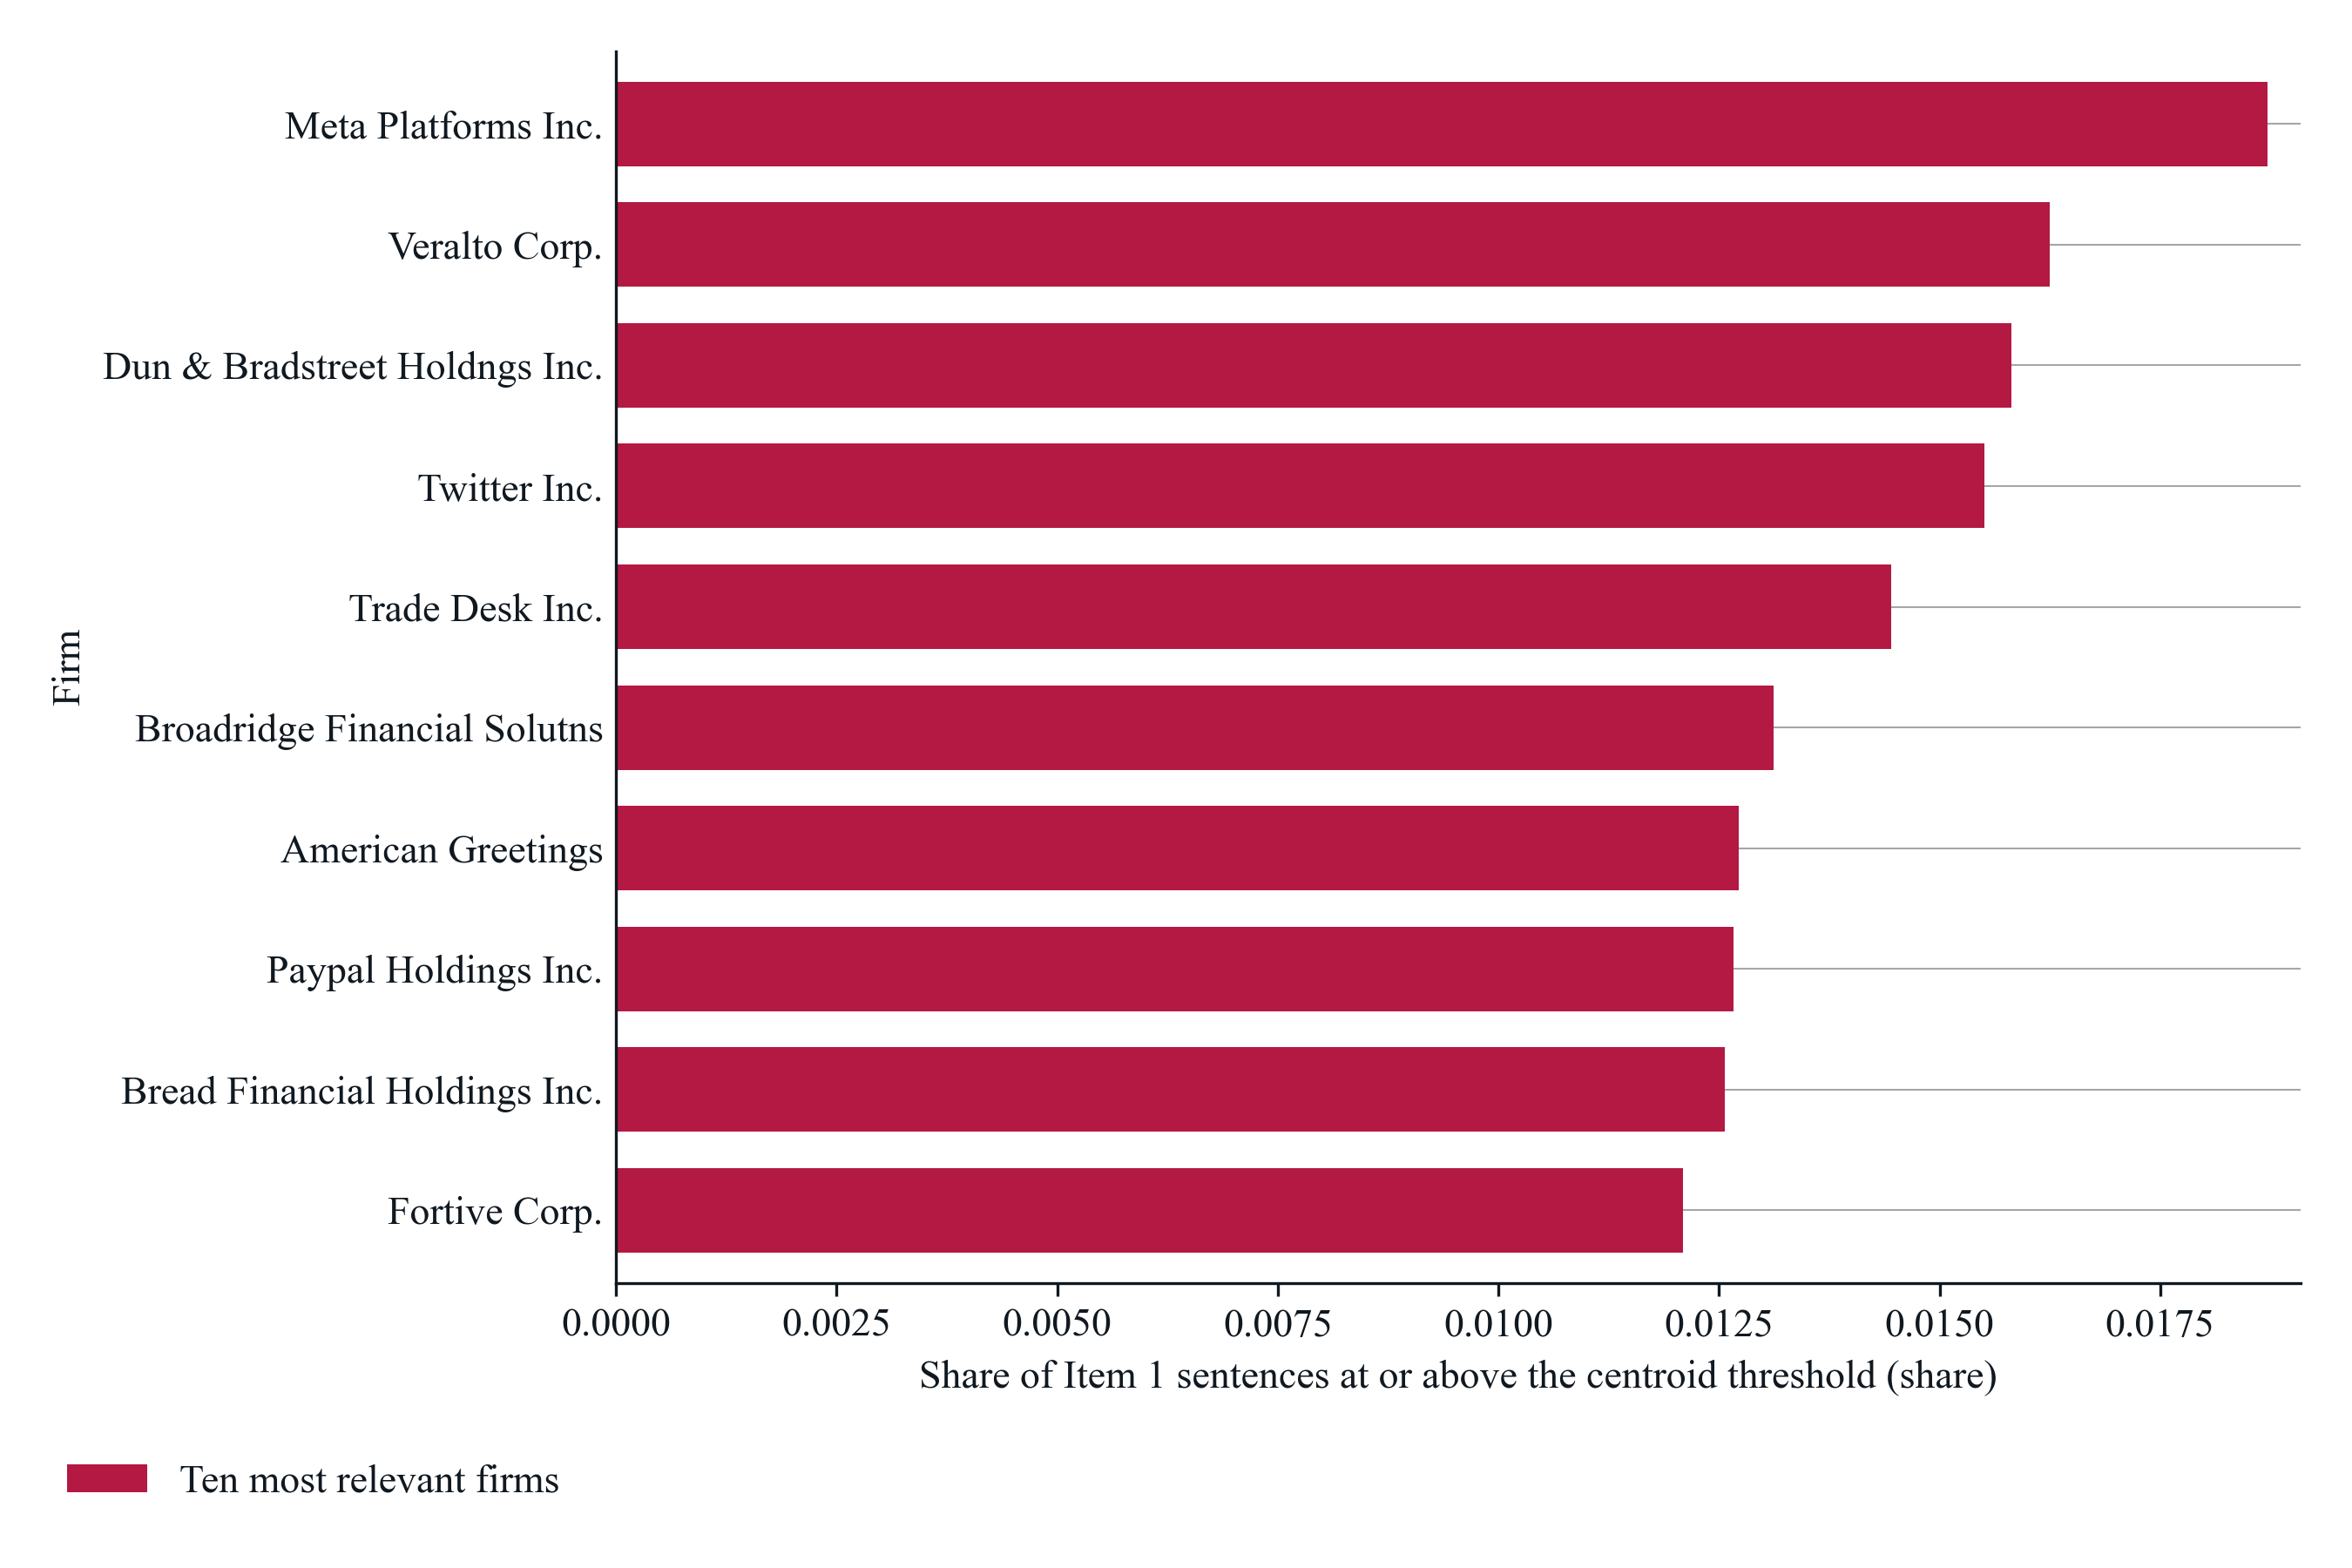

*Notes*: Bars show the score, which is the number of the firm's Item 1 sentences whose cosine with the statement centroid is at or above 0.75, divided by all its Item 1 sentences in the sample, compared with the statement centroid of Topic 68, consumer data privacy legislation, for the firms ranked highest among the 1,058 scored firms of the all-years sample (every fiscal year a firm filed, 1999 to 2025). The ten least relevant firms are not drawn because 793 firms tie at the minimum score of 0.000. Firm names are Compustat names in title case.

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; firm names from Compustat; authors' calculations.

**Figure 3. Most and Least Relevant Firms by the Firm Summary Cosine with the Definition Vector**

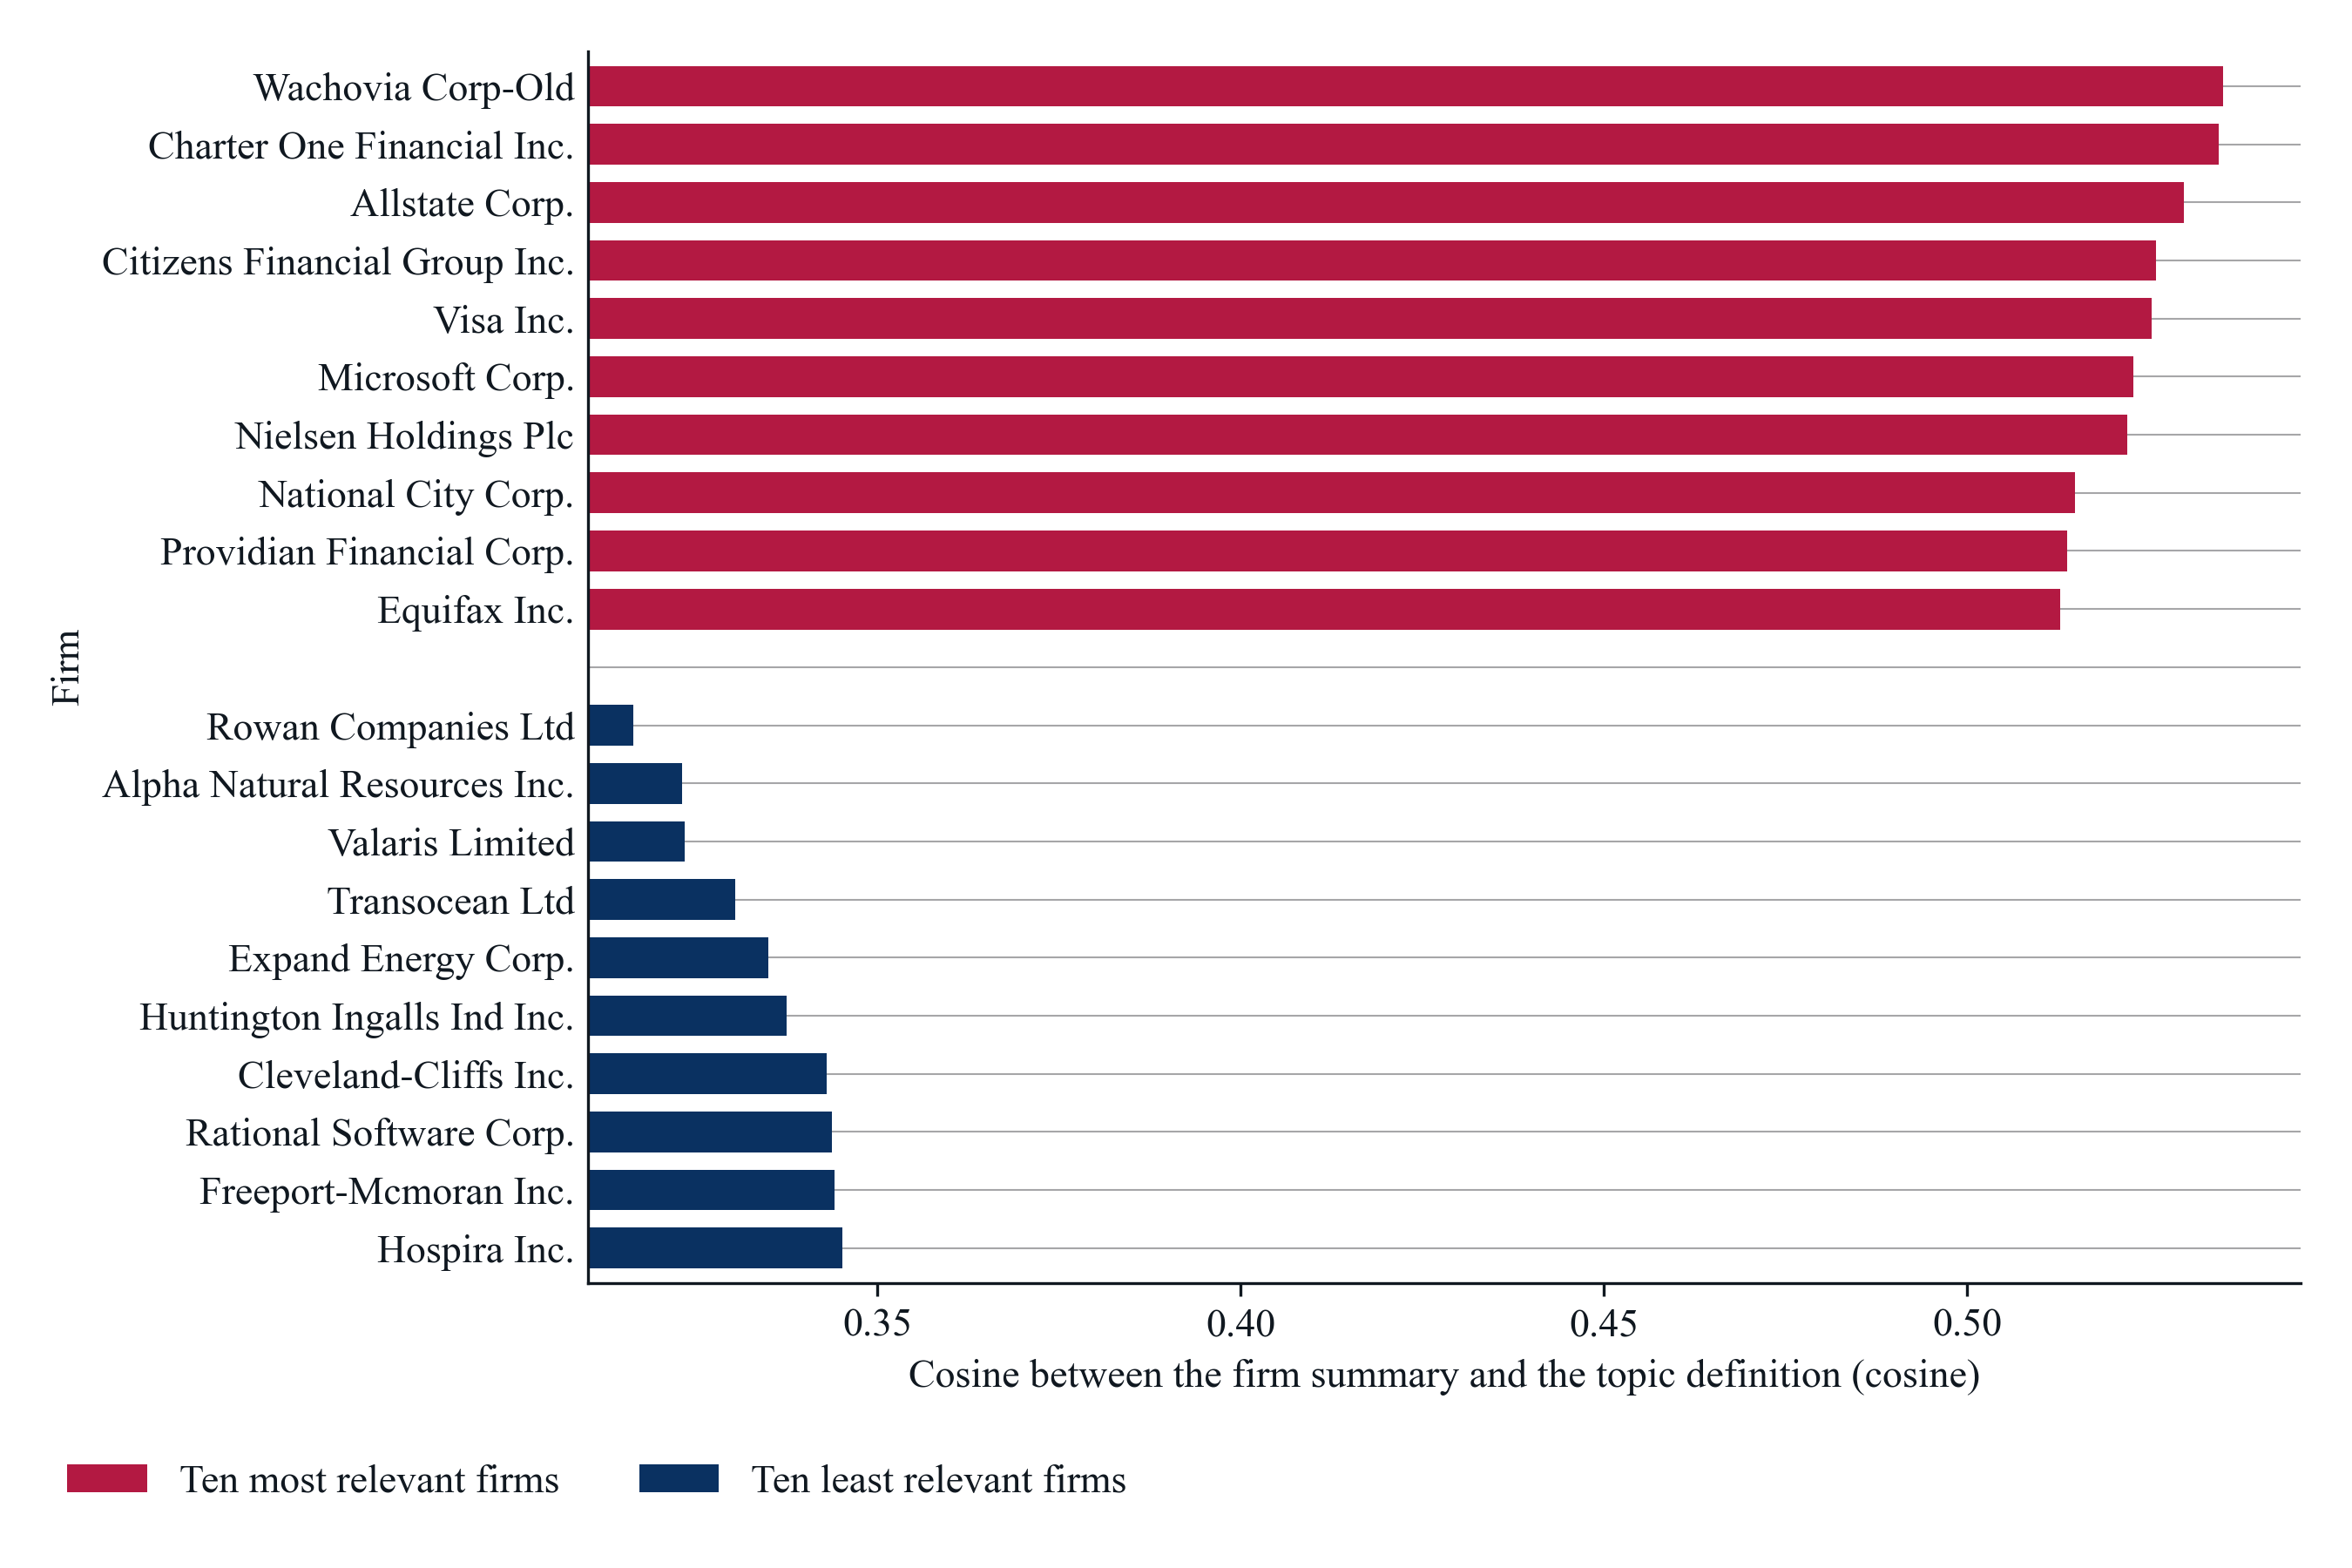

*Notes*: Bars show the score, which is the cosine between the embedding of the firm's summary of its Item 1 sections and the embedding of the topic definition, compared with the topic definition of Topic 68, consumer data privacy legislation, for the firms ranked highest and lowest among the 1,058 scored firms of the all-years sample (every fiscal year a firm filed, 1999 to 2025). Firm names are Compustat names in title case.

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; firm names from Compustat; authors' calculations.

**Figure 4. Most and Least Relevant Firms by the Yearly Summary Mean Cosine with the Definition Vector**

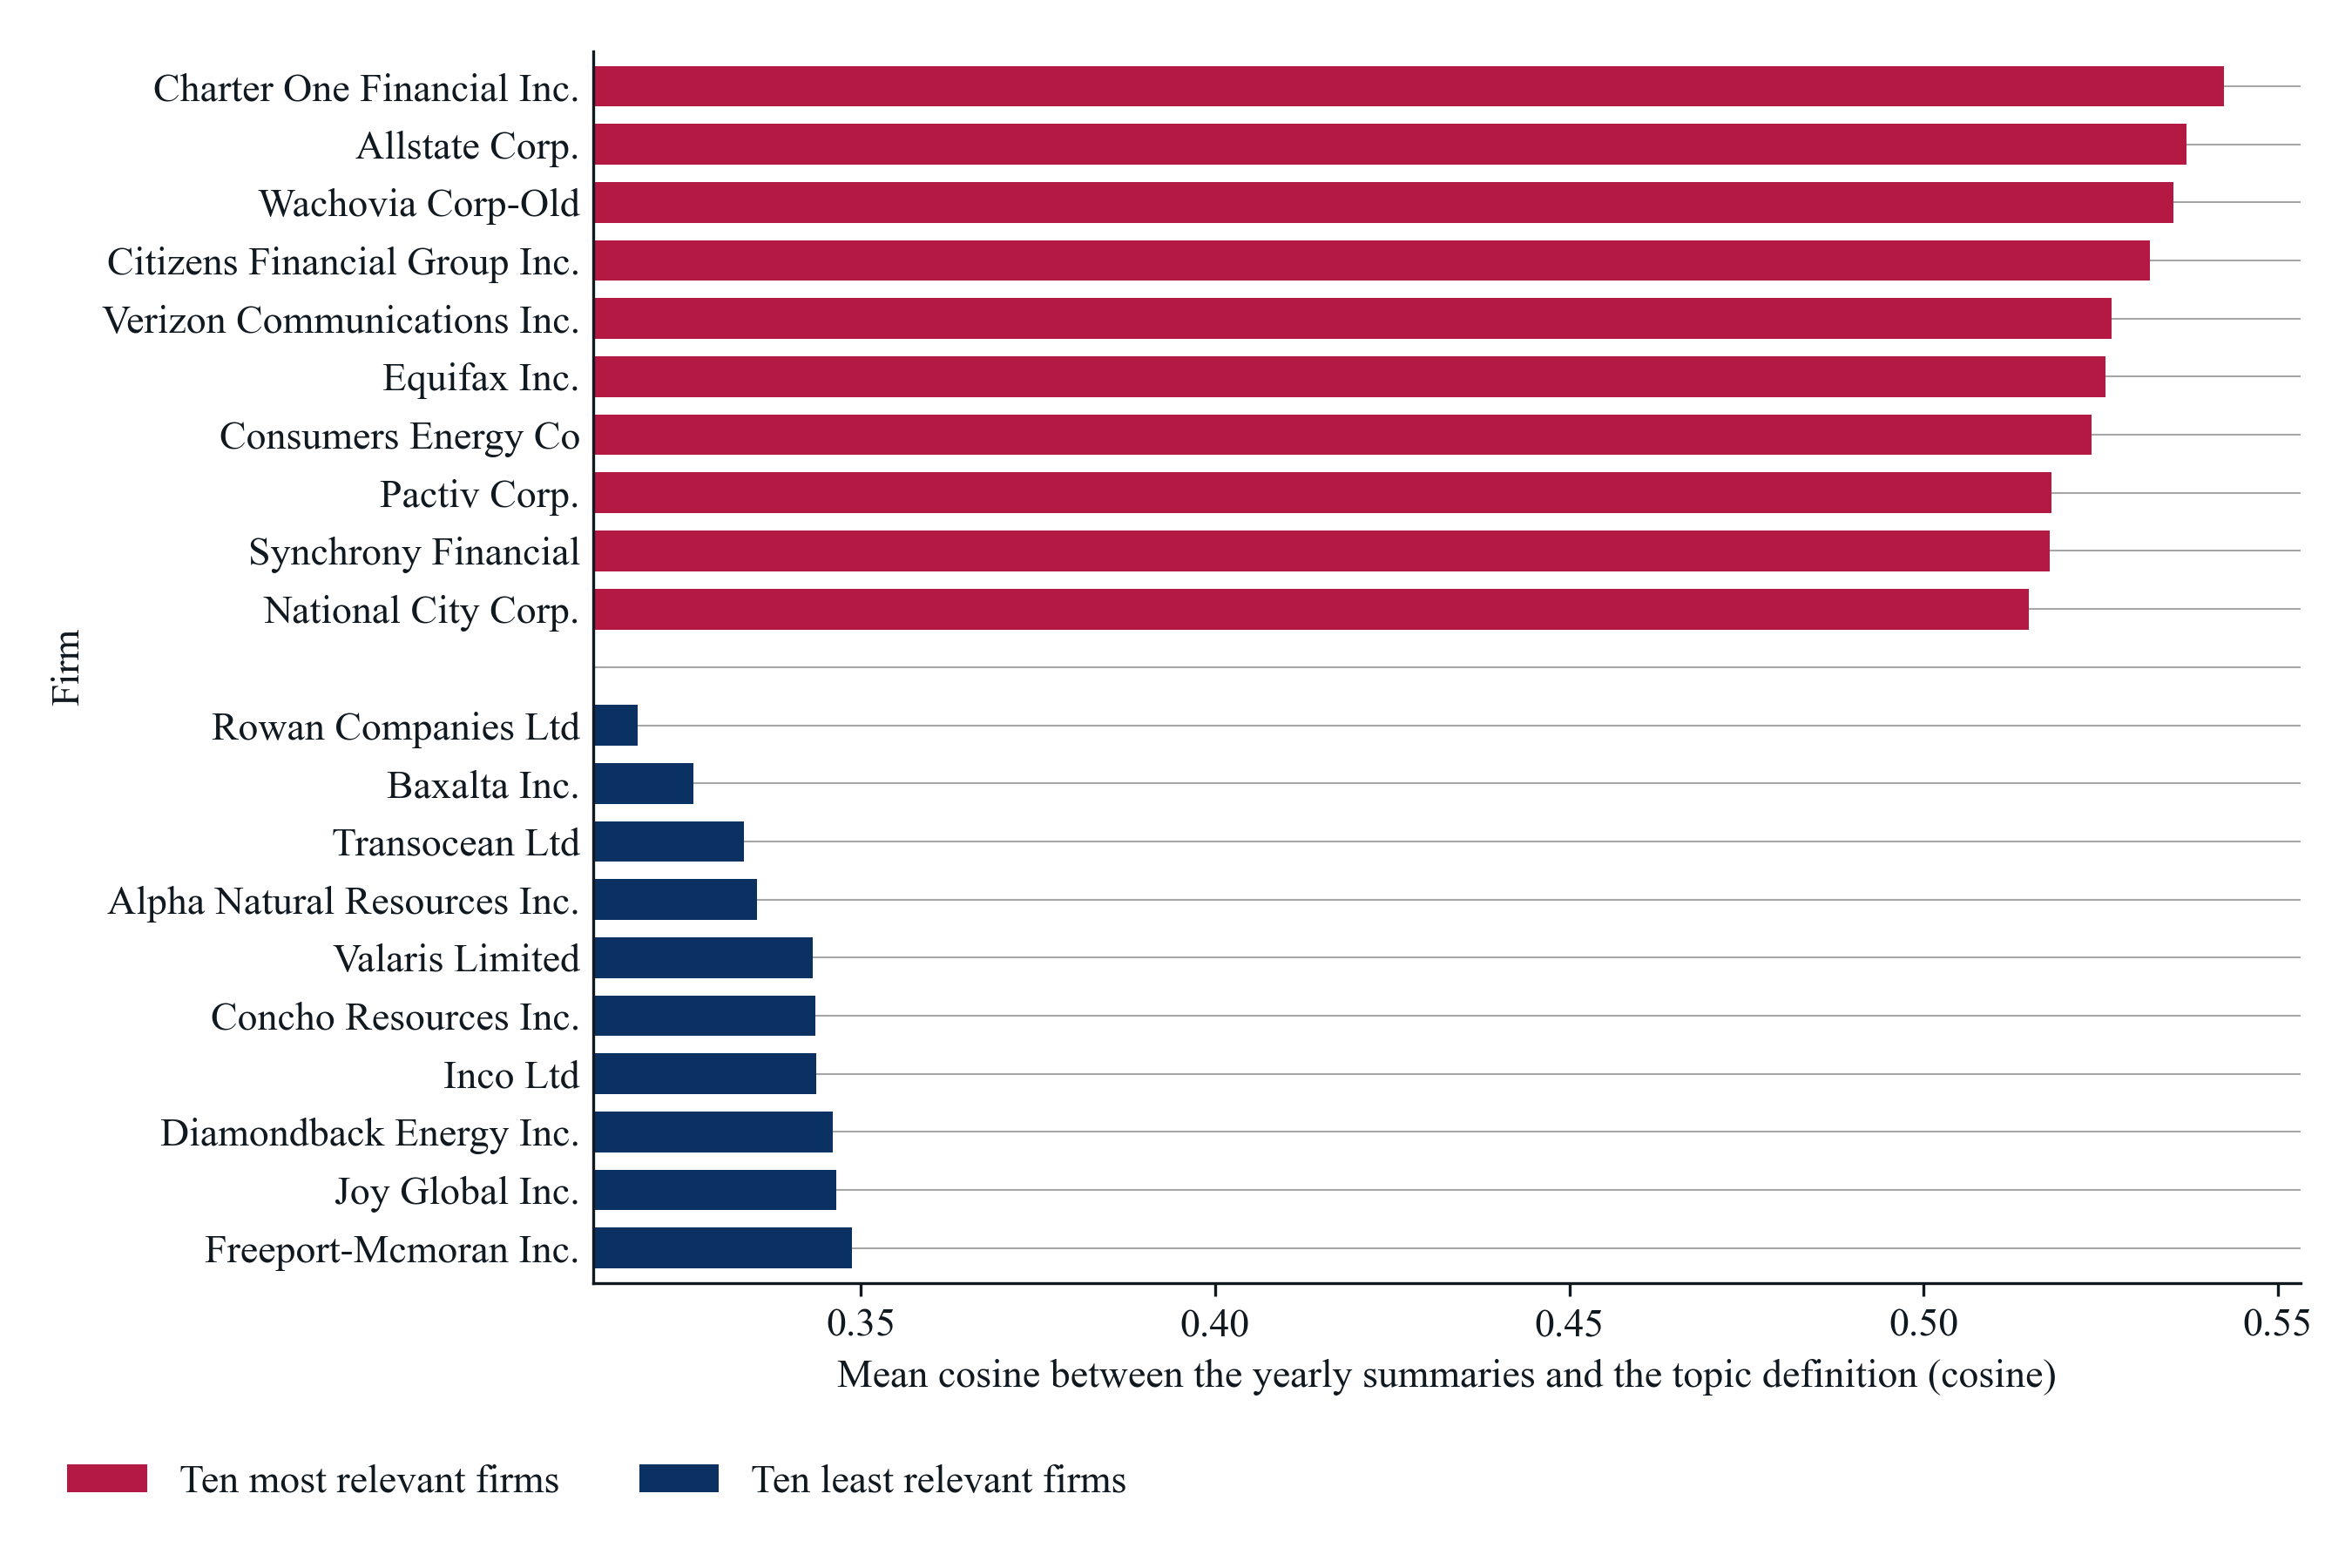

*Notes*: Bars show the score, which is the cosine between each yearly Item 1 summary and the topic definition, averaged over the firm's fiscal years in the sample, compared with the topic definition of Topic 68, consumer data privacy legislation, for the firms ranked highest and lowest among the 1,058 scored firms of the all-years sample (every fiscal year a firm filed, 1999 to 2025). Firm names are Compustat names in title case.

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; firm names from Compustat; authors' calculations.

**Figure 5. Most and Least Relevant Firms by the Firm Summary Cosine with the Centroid Vector**

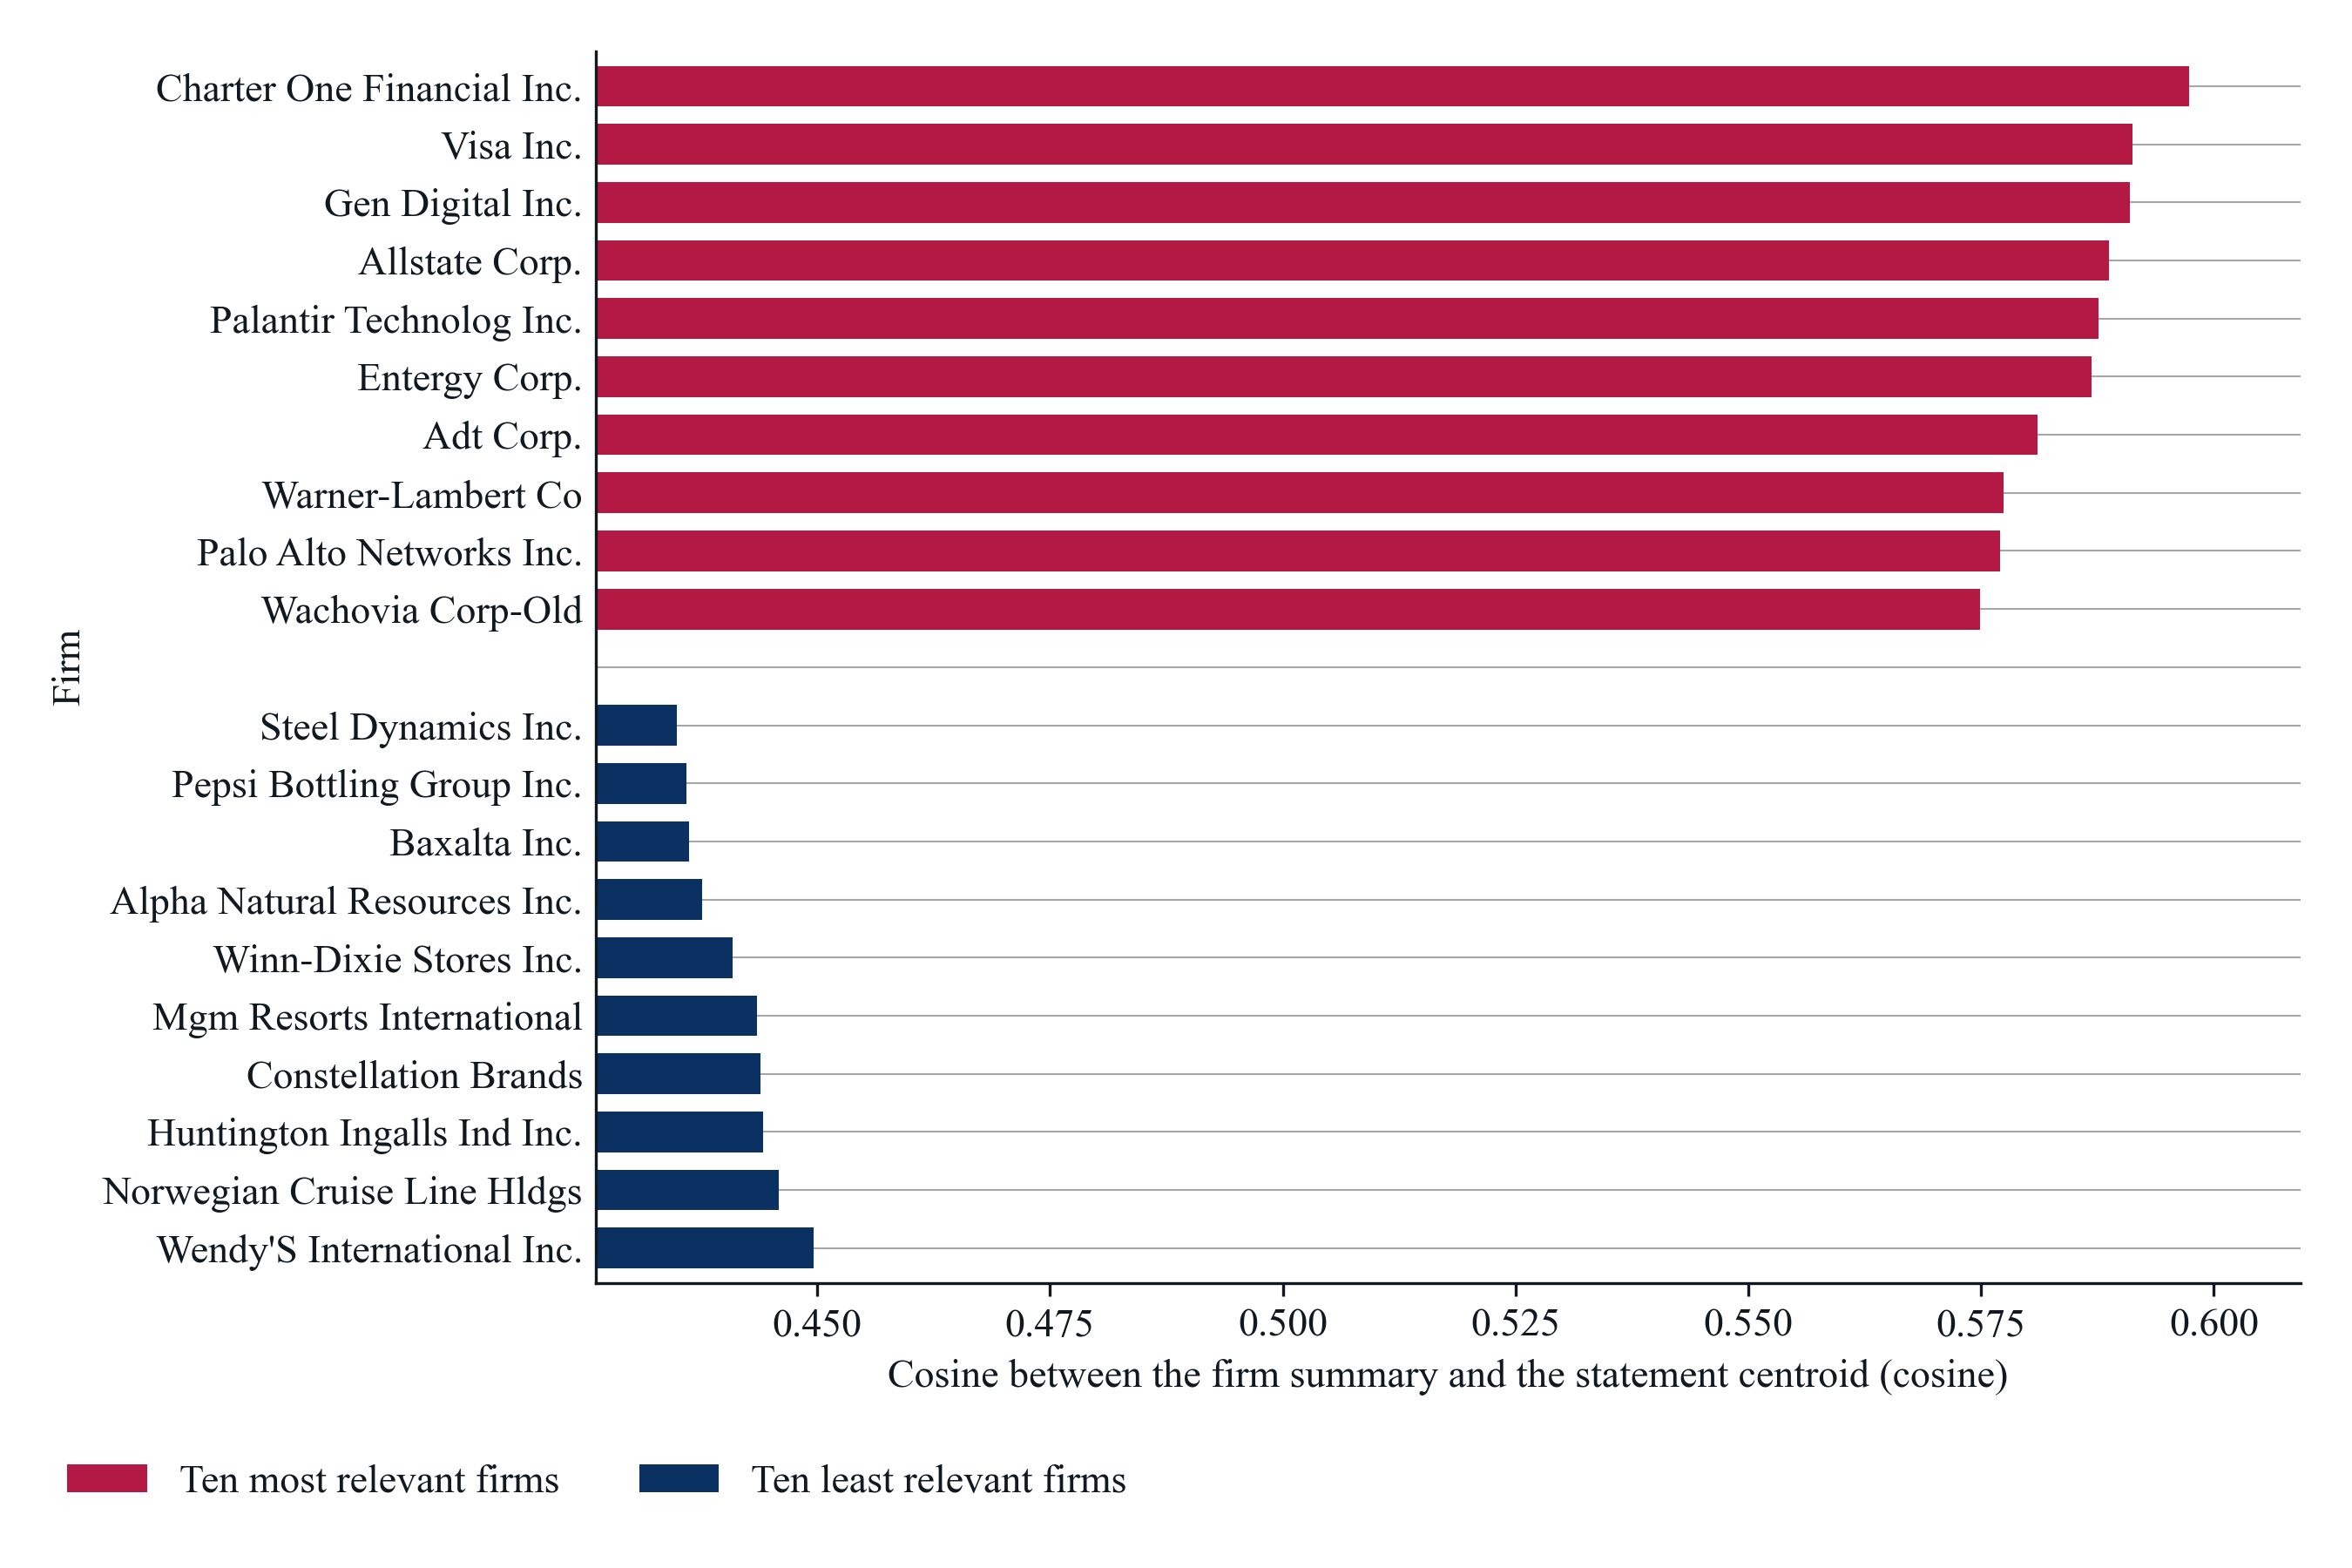

*Notes*: Bars show the score, which is the cosine between the embedding of the firm's summary of its Item 1 sections and the centroid of the Topic 68 hearing statements, compared with the statement centroid of Topic 68, consumer data privacy legislation, for the firms ranked highest and lowest among the 1,058 scored firms of the all-years sample (every fiscal year a firm filed, 1999 to 2025). Firm names are Compustat names in title case.

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; firm names from Compustat; authors' calculations.

**Figure 6. Most and Least Relevant Firms by the Yearly Summary Mean Cosine with the Centroid Vector**

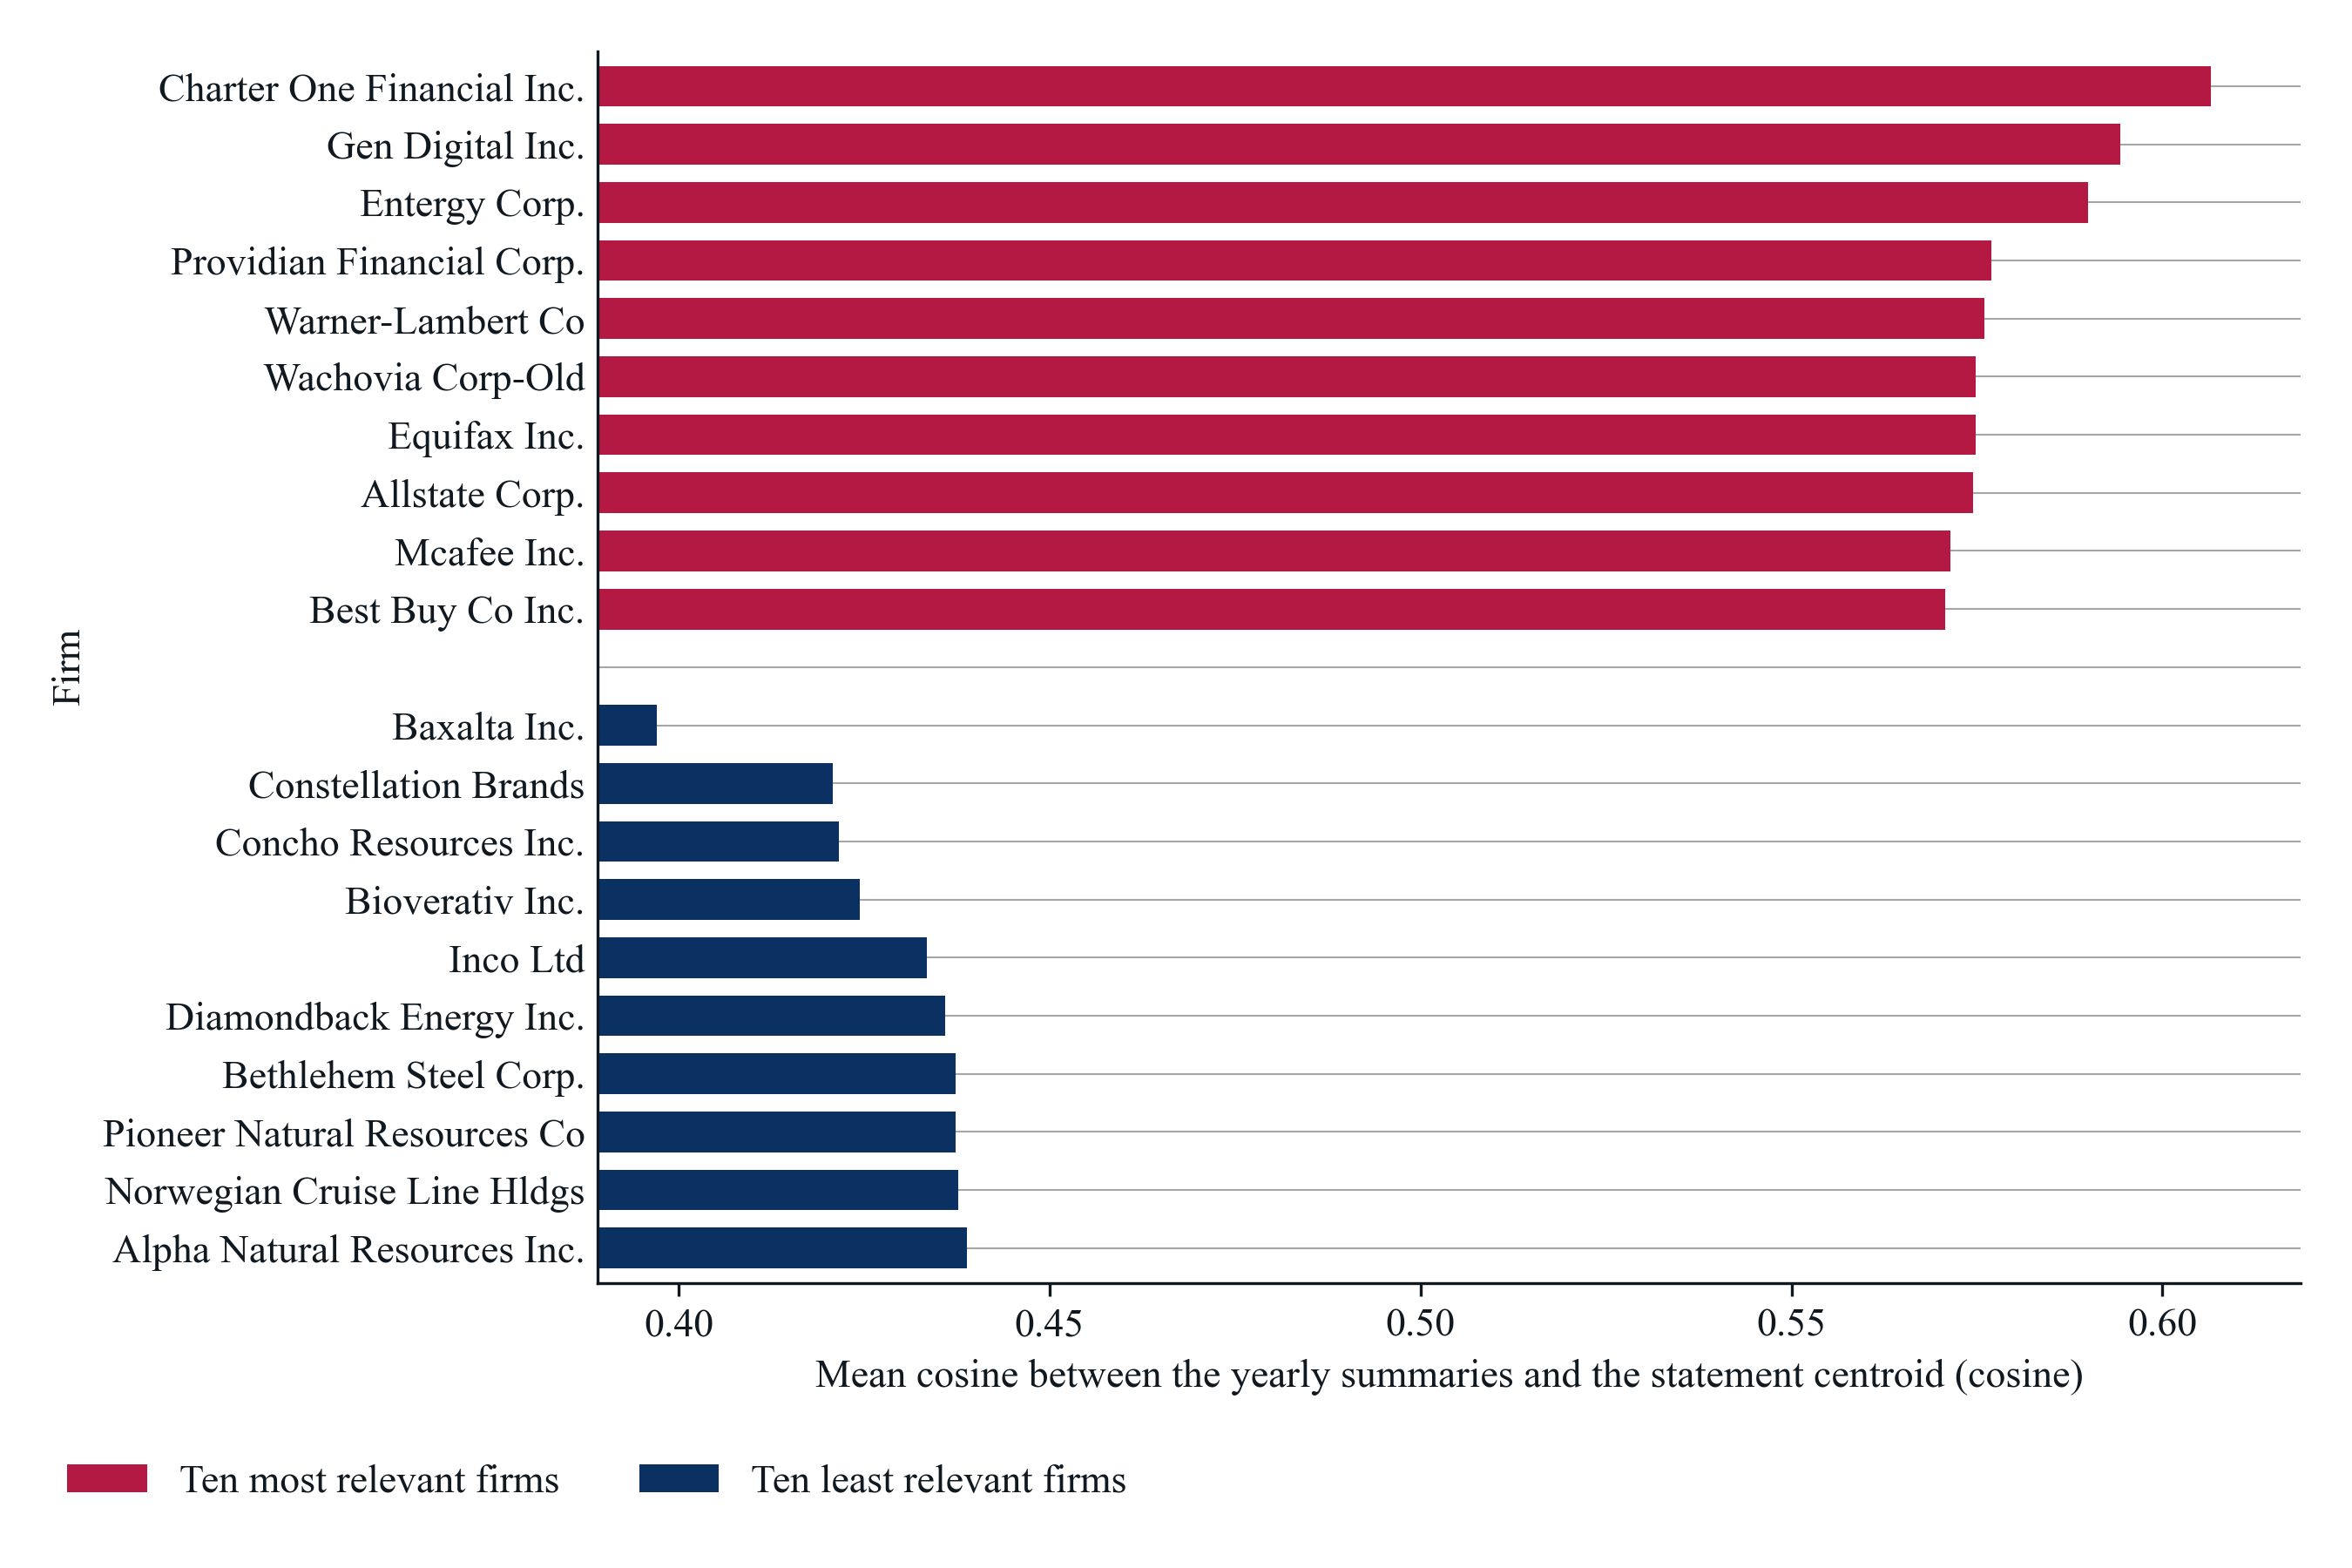

*Notes*: Bars show the score, which is the cosine between each yearly Item 1 summary and the centroid of the Topic 68 hearing statements, averaged over the firm's fiscal years in the sample, compared with the statement centroid of Topic 68, consumer data privacy legislation, for the firms ranked highest and lowest among the 1,058 scored firms of the all-years sample (every fiscal year a firm filed, 1999 to 2025). Firm names are Compustat names in title case.

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; firm names from Compustat; authors' calculations.

**Figure 7. Most and Least Relevant Firms by the Firm Summary Cosine with the Policy Summary Vector**

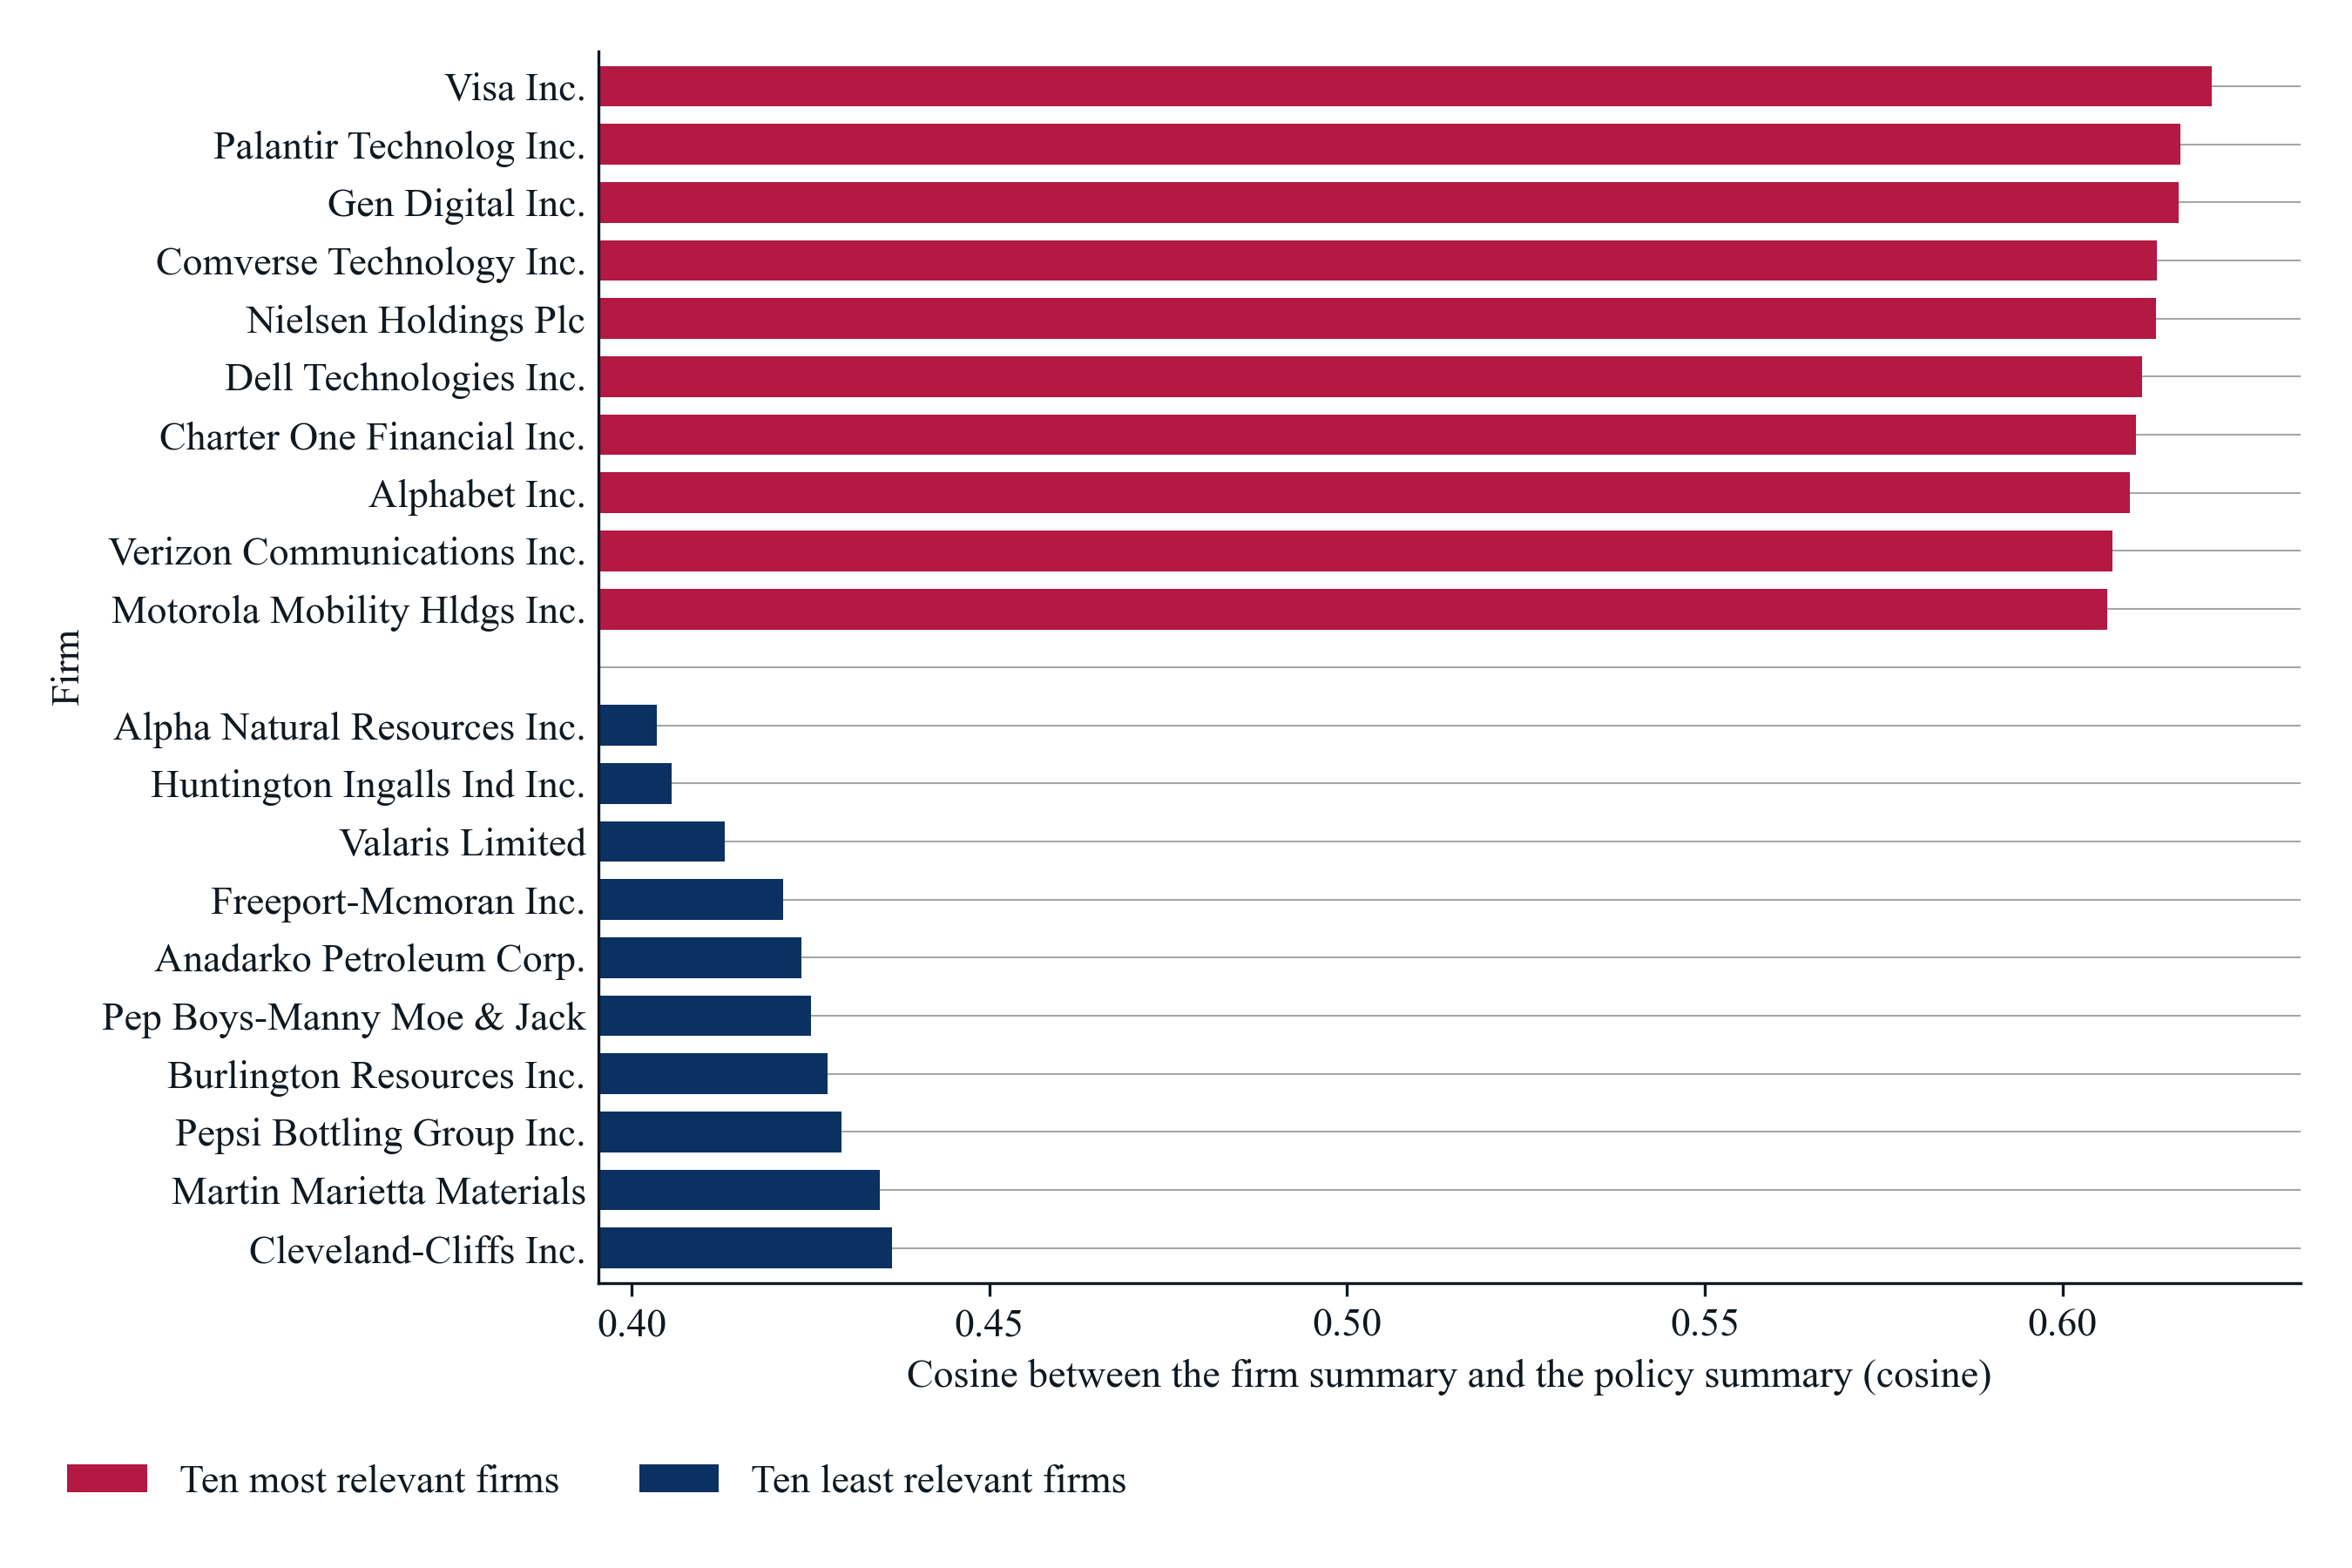

*Notes*: Bars show the score, which is the cosine between the embedding of the firm's summary of its Item 1 sections and the embedding of the policy summary of the Topic 68 hearing statements, compared with the policy summary of Topic 68, consumer data privacy legislation, for the firms ranked highest and lowest among the 1,058 scored firms of the all-years sample (every fiscal year a firm filed, 1999 to 2025). Firm names are Compustat names in title case.

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; firm names from Compustat; authors' calculations.

**Figure 8. Most and Least Relevant Firms by the Yearly Summary Mean Cosine with the Policy Summary Vector**

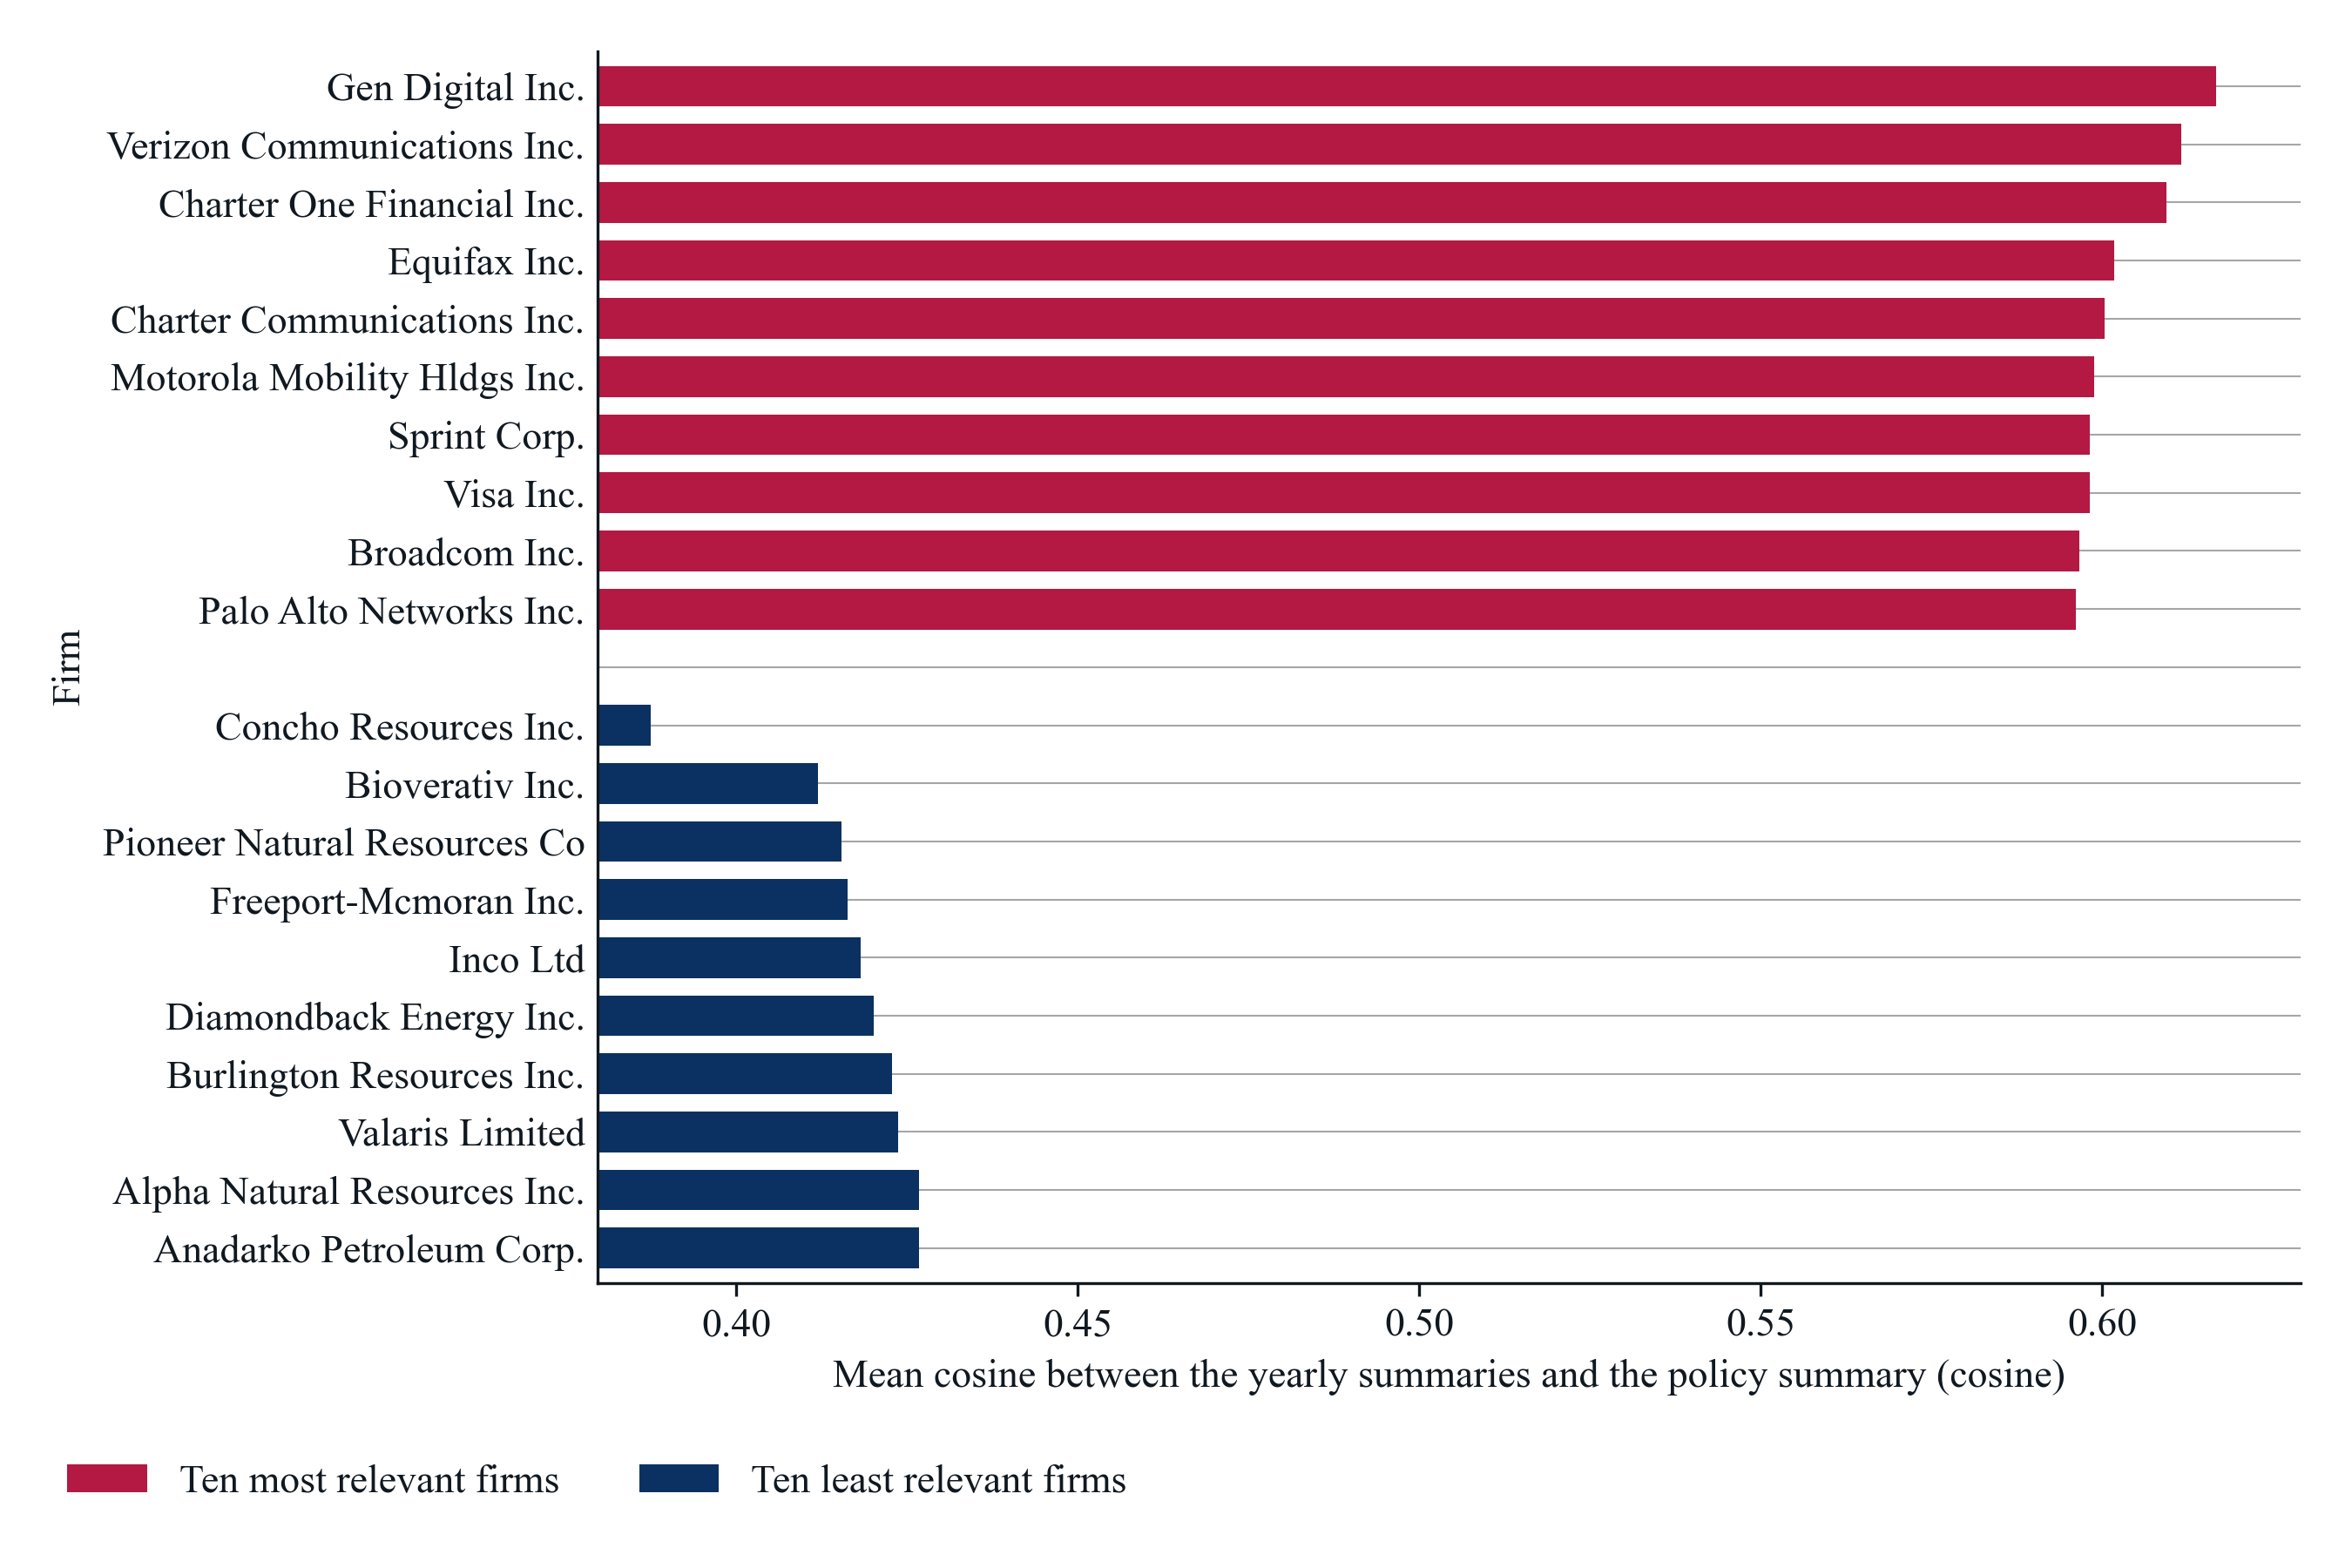

*Notes*: Bars show the score, which is the cosine between each yearly Item 1 summary and the policy summary of the Topic 68 hearing statements, averaged over the firm's fiscal years in the sample, compared with the policy summary of Topic 68, consumer data privacy legislation, for the firms ranked highest and lowest among the 1,058 scored firms of the all-years sample (every fiscal year a firm filed, 1999 to 2025). Firm names are Compustat names in title case.

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; firm names from Compustat; authors' calculations.

In [6]:
MEASURE_TITLES = {"share": "Share of Sentences", "firm_summary": "Firm Summary Cosine", "yearly_mean": "Yearly Summary Mean Cosine"}
VECTOR_TITLES = {"definition": "Definition Vector", "centroid": "Centroid Vector", "policy_summary": "Policy Summary Vector"}
for figure_number, figure_name, measure_id, notes, show_bottom in figure_records:
    method, vector, measure = [part.strip() for part in measure_id.split("|")]
    group_words = "Most and Least Relevant Firms" if show_bottom else "Most Relevant Firms"
    display(Markdown(f"**Figure {figure_number}. {group_words} by the {MEASURE_TITLES[measure]} with the {VECTOR_TITLES[vector]}**"))
    display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
    display(Markdown(f"*Notes*: {notes}"))
    display(Markdown(f"*Source*: {SOURCE}."))
